### ĆW 1

- Zbuduj potok dla obrazu:
  - zmień rozmiar na 224 x 224
  - zastosuj dwie metody wstępnego przetwarzania
  - zbuduj potok Albumentations z 4 przekształceń
  - korzystając z pyplot, zaprezentuj osiem wariantów obrazu
- Policz podobieństwo obrazu oryginalnego, do każdego z obrazów uzyskanych w potoku (spłaszczanie i pod. kosinusowe)

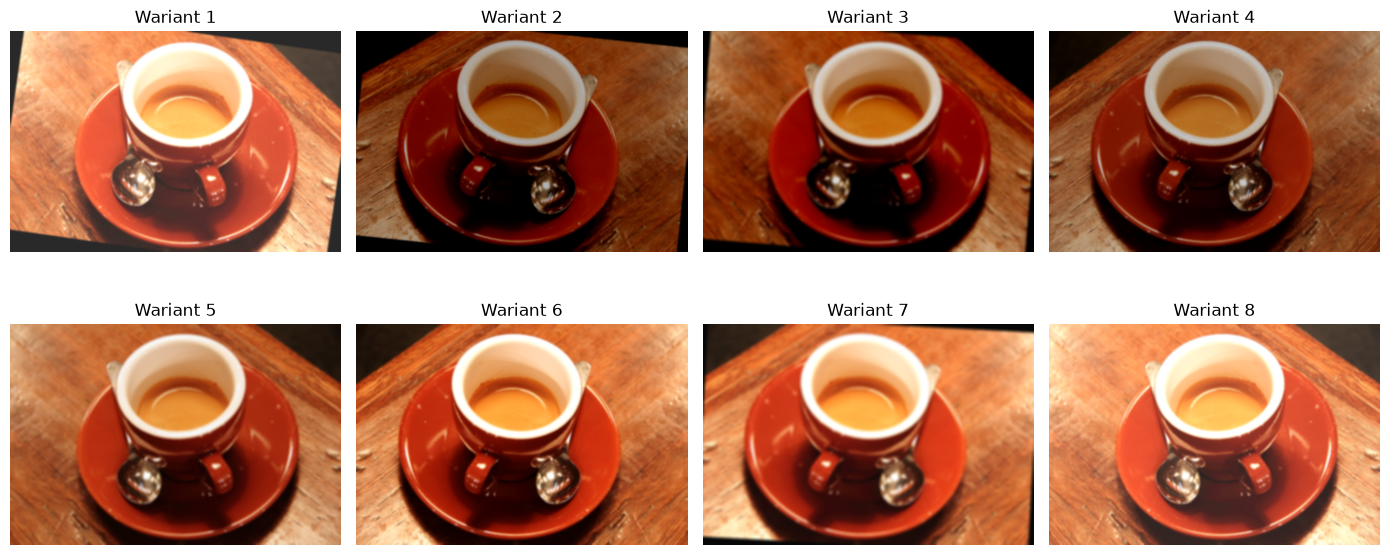

0.8592
0.9137
0.8026
0.9945
0.8653
0.995
0.9675
0.8788


In [4]:
from skimage import data
from skimage import transform, color
import numpy as np
import matplotlib.pyplot as plt

image = data.coffee()

resized = transform.resize(image, (224, 224), anti_aliasing=True)
resized = (resized * 255).astype(np.uint8)

flipped = resized[::-1, :]

# ...

import albumentations as A

pipeline = A.Compose([
  A.HorizontalFlip(p=0.5),
  A.Rotate(limit=10, p=0.75),
  A.RandomBrightnessContrast(p=0.9),
  # A.CenterCrop(100, 100, p=0.5),
  A.GaussianBlur(blur_limit=(5,9), p=0.9)
])

augmented_images = []
fig, axes = plt.subplots(2, 4, figsize=(14, 6.5))
for i, ax in enumerate(axes.flat):
  augmented = pipeline(image=image)["image"] 
  ax.imshow(augmented)  
  ax.set_title(f"Wariant {i + 1}")
  ax.axis("off")
  augmented_images.append(augmented)
plt.tight_layout()
plt.show()

def cosine_similarity(a, b):
  return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))

splaszczony_image = image.astype(np.float32).flatten()

for augmented in augmented_images:
  splaszczony_augment = augmented.astype(np.float32).flatten()
  print(round(cosine_similarity(splaszczony_image, splaszczony_augment), 4))